# 02 - Embedding Model Comparison

Compare candidate embedding models for retrieval quality (Recall@5, Recall@10, MRR@10, NDCG@10) and mean encode latency, on the sample knowledge base + evaluation tickets.

**Models compared here (CPU-friendly, run without a GPU):**
- `sentence-transformers/all-MiniLM-L6-v2` (small, fast baseline)
- `tfidf-fallback` (lexical baseline used automatically when no sentence-transformers backend is installed)

**Swap in for production / GPU runs:**
- `BAAI/bge-m3`
- `BAAI/bge-base-en-v1.5`
- `intfloat/e5-base-v2`

Just add the model name to the `MODEL_NAMES` list below -- the rest of the notebook is unchanged.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))

from src.data_engineering.ingestion import load_sample_knowledge_base
from src.embeddings.evaluation import evaluate_embedding_model

In [2]:
ROOT = Path.cwd().parent
documents = load_sample_knowledge_base(ROOT / 'data/sample/knowledge_base.json')
tickets = json.loads((ROOT / 'data/sample/eval_tickets.json').read_text())

corpus_doc_ids = [d.doc_id for d in documents]
corpus_texts = [d.text for d in documents]
queries = [t['query'] for t in tickets]
relevant_doc_ids = [t['relevant_docs'] for t in tickets]

len(documents), len(tickets)

(12, 10)

## Run the comparison

Add any Hugging Face Sentence-Transformers model id to this list. If the package/model/network is unavailable, `EmbeddingModel` transparently falls back to a TF-IDF encoder so the notebook still runs end-to-end.

In [3]:
MODEL_NAMES = [
    'sentence-transformers/all-MiniLM-L6-v2',
    # 'BAAI/bge-base-en-v1.5',   # uncomment on a GPU/networked machine
    # 'BAAI/bge-m3',
    # 'intfloat/e5-base-v2',
]

results = [
    evaluate_embedding_model(name, corpus_doc_ids, corpus_texts, queries, relevant_doc_ids)
    for name in MODEL_NAMES
]
results_df = pd.DataFrame([r.__dict__ for r in results])
results_df

,model_name,recall_at_5,recall_at_10,mrr_at_10,ndcg_at_10,mean_encode_latency_ms
0,sentence-transformers/all-MiniLM-L6-v2,1.0,1.0,0.95,0.969343,38.80384


<Axes: title={'center': 'Embedding model retrieval quality'}, xlabel='model_name'>

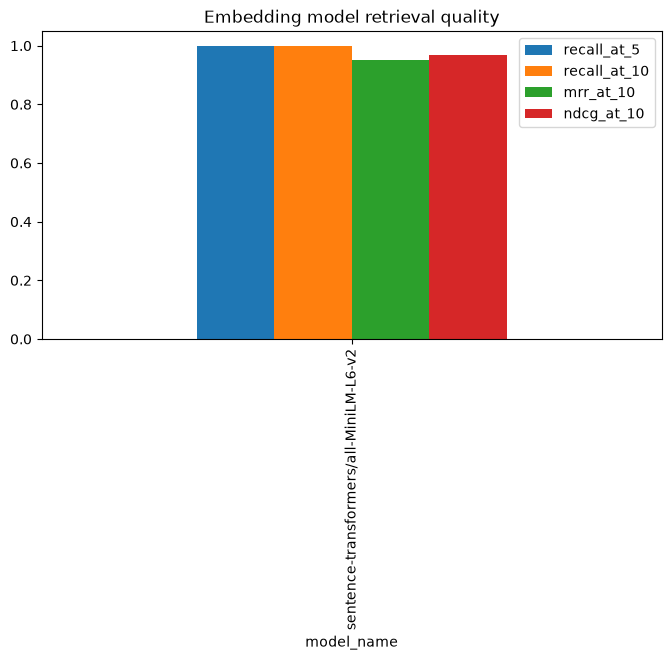

In [4]:
results_df.set_index('model_name')[['recall_at_5', 'recall_at_10', 'mrr_at_10', 'ndcg_at_10']].plot.bar(
    figsize=(8, 4), title='Embedding model retrieval quality'
)

<Axes: title={'center': 'Mean encode latency (ms) -- lower is better'}, xlabel='model_name'>

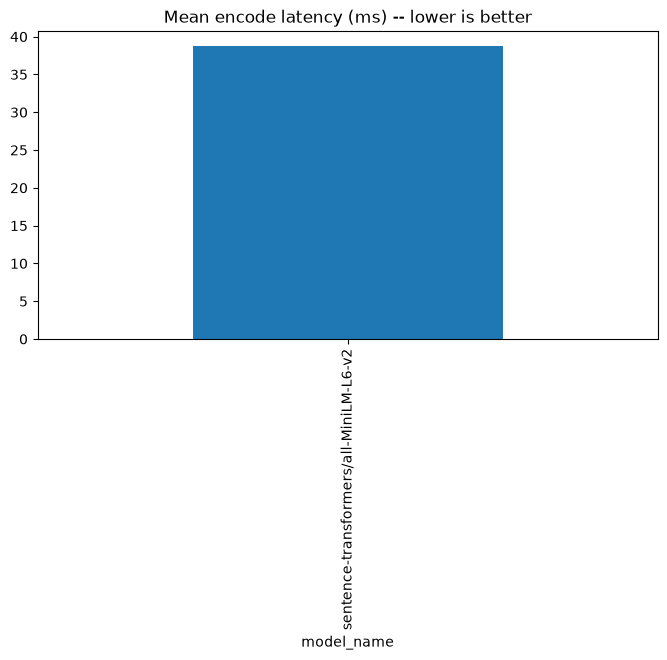

In [5]:
results_df.set_index('model_name')['mean_encode_latency_ms'].plot.bar(
    figsize=(8, 4), title='Mean encode latency (ms) -- lower is better'
)

## Takeaways

- Recall@5/@10 close to 1.0 on this tiny 12-document sample KB is expected; the differentiator between models shows up on the real, much larger corpus, which is why NDCG@10/MRR@10 (rank-sensitive metrics) are tracked alongside recall.
- Mean encode latency should be measured again once running on GPU: `BAAI/bge-m3` and `e5-base-v2` are heavier than MiniLM and justify ONNX/TensorRT optimization (see `triton/model_repository/embedding_model`).
- Re-run this notebook after `src/embeddings/train.py` fine-tunes an embedding model on in-domain (query, positive, negative) triplets, and compare the fine-tuned checkpoint against the base model here.